In [1]:

from PIL import Image
from torchvision import transforms
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch.nn.functional as F

import ast

import matplotlib.pyplot as plt
import numpy as np

import torch.nn as nn
from PIL import Image


from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from pathlib import Path
import torch
from safetensors.torch import load_file
from transformers import AutoConfig, AutoModelForImageClassification



import ast


import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [2]:
label_to_id = pd.read_csv("Data/label_to_id_mapping.csv").set_index("label")["id"].to_dict()
dx=pd.read_csv("Data/Test_set.csv")

bboxes_frame = pd.read_csv("Data/collected_data.csv")
df=dx.copy()
label_mapping=pd.read_csv("Data/label_to_id_mapping.csv")

X=dx["X"].tolist()


dx["ID"]=dx["X"].str.split("/").str[-1]
dx["ID"]=dx["ID"].str.split(".").str[0]



In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])


In [4]:

model_dir = Path("best_model")


config = AutoConfig.from_pretrained(model_dir,local_files_only=True,)

classes = label_mapping["label"].tolist()



config.id2label = {i: label for i, label in enumerate(classes)}
config.label2id = {label: i for i, label in enumerate(classes)}


model = AutoModelForImageClassification.from_config(config)

old_state_dict = load_file(model_dir / "model.safetensors",device="cpu")


def convert_vit_key(key):
    key = key.replace(
        "vit.encoder.layer.",
        "vit.layers.",
        1,
    )
    replacements = {
        ".attention.attention.query.": ".attention.q_proj.",
        ".attention.attention.key.": ".attention.k_proj.",
        ".attention.attention.value.": ".attention.v_proj.",
        ".attention.output.dense.": ".attention.o_proj.",
        ".intermediate.dense.": ".mlp.fc1.",
        ".output.dense.": ".mlp.fc2.",
    }

    for old, new in replacements.items():
        key = key.replace(old, new)

    return key


new_state_dict = {
    convert_vit_key(key): tensor
    for key, tensor in old_state_dict.items()
}



load_result = model.load_state_dict(new_state_dict,strict=True,)


W1111 14:02:03.948000 41976 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [5]:
cam_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])



annotations_by_id = bboxes_frame.set_index("id")
prepared_inputs, image_id, bbox = [], [], []

for image_idx in range(100):
    image_path = df["X"].iloc[image_idx]
    code = Path(image_path).stem

    annotation = annotations_by_id.loc[code]
    boxes = ast.literal_eval(annotation["bboxes"])
    labels = ast.literal_eval(annotation["labels"])

    leading_boxes = [box for box, label in zip(boxes, labels) if label != "no_gesture"]

    with Image.open(image_path) as image:
        input_tensor = cam_transform(image.convert("RGB")).unsqueeze(0)

    prepared_inputs.append(input_tensor)
    image_id.append(code)
    bbox.append(leading_boxes)

In [6]:

class ViTLogitsWrapper(nn.Module):
    def __init__(self, vit_model):
        super().__init__()
        self.vit_model = vit_model

    def forward(self, pixel_values):
        return self.vit_model(
            pixel_values=pixel_values
        ).logits


device = next(model.parameters()).device
model.eval()

cam_model = ViTLogitsWrapper(model)
cam_model.to(device)
cam_model.eval()

ViTLogitsWrapper(
  (vit_model): ViTForImageClassification(
    (vit): ViTModel(
      (embeddings): ViTEmbeddings(
        (patch_embeddings): ViTPatchEmbeddings(
          (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (layers): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (q_proj): Linear(in_features=192, out_features=192, bias=True)
            (k_proj): Linear(in_features=192, out_features=192, bias=True)
            (v_proj): Linear(in_features=192, out_features=192, bias=True)
            (o_proj): Linear(in_features=192, out_features=192, bias=True)
          )
          (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
          (mlp): ViTMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=192, ou

In [7]:

def reshape_transform(tensor):
    B, N, C = tensor.shape
    if N == 197:
        tensor = tensor[:, 1:, :]
    elif N == 198:
        tensor = tensor[:, 2:, :]
    else:
        raise ValueError(f"Unerwartete Token-Anzahl: {N}")
    tensor = tensor.reshape(B, 14, 14, C)
    return tensor.permute(0, 3, 1, 2).contiguous()



if hasattr(model, "deit"):
    backbone = model.deit
else:
    backbone = model.vit

if hasattr(backbone, "layers"):
    layers = backbone.layers
else:
    layers = backbone.encoder.layer


In [8]:
def model_prediction(input_tensor):
    with torch.no_grad():
        logits = cam_model(input_tensor)
        probabilities = torch.softmax(logits,dim=1)

    predicted_class = int(
        probabilities.argmax(dim=1).item()
    )

    confidence = float(
        probabilities[0, predicted_class].item()
    )

    class_name = model.config.id2label.get(
        predicted_class,
        str(predicted_class),
    )
    return class_name, predicted_class, confidence


Processing image 1/100


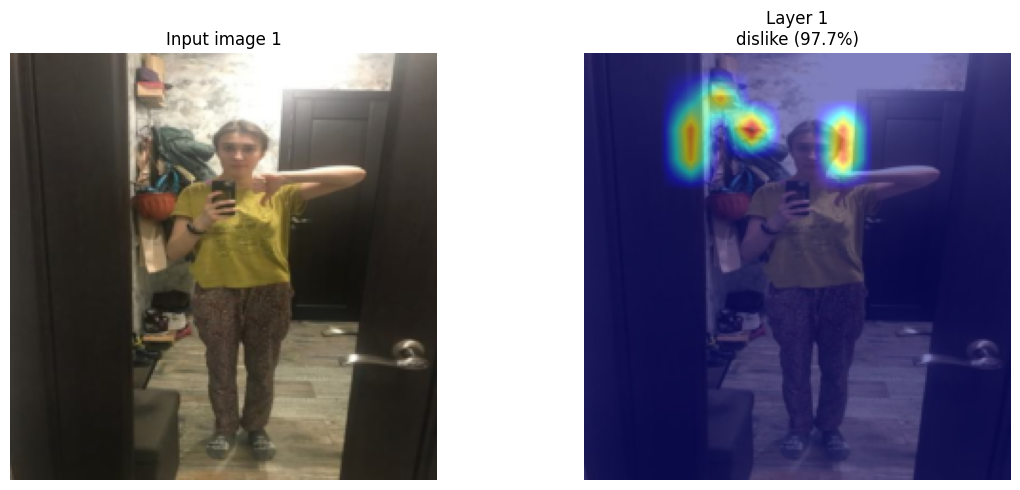

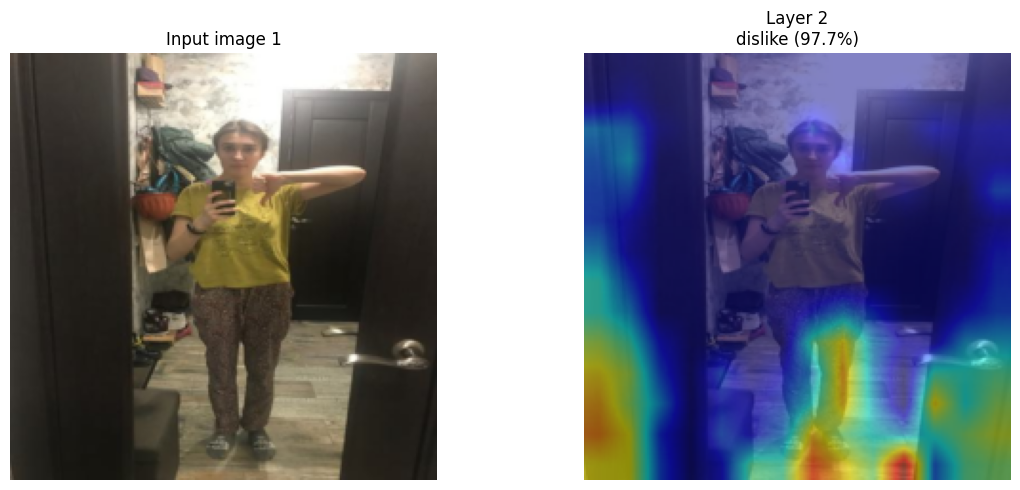

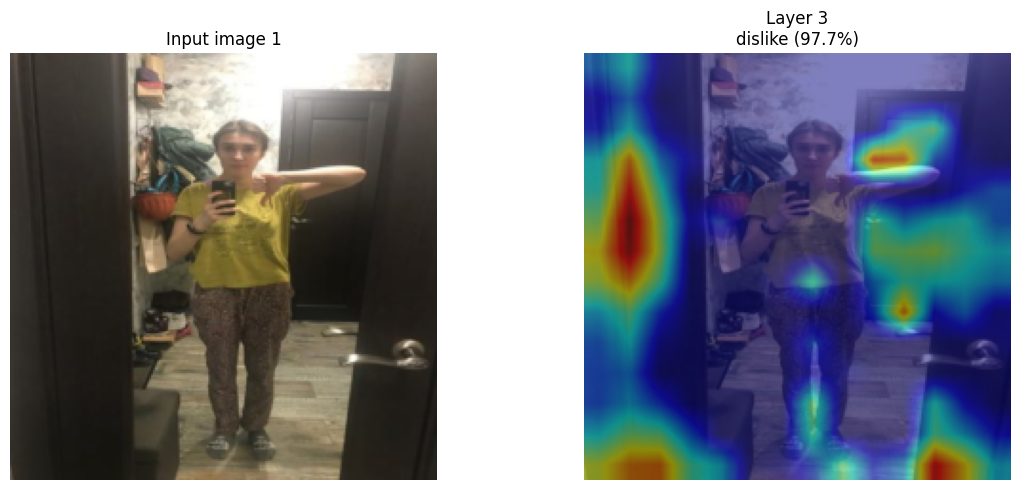

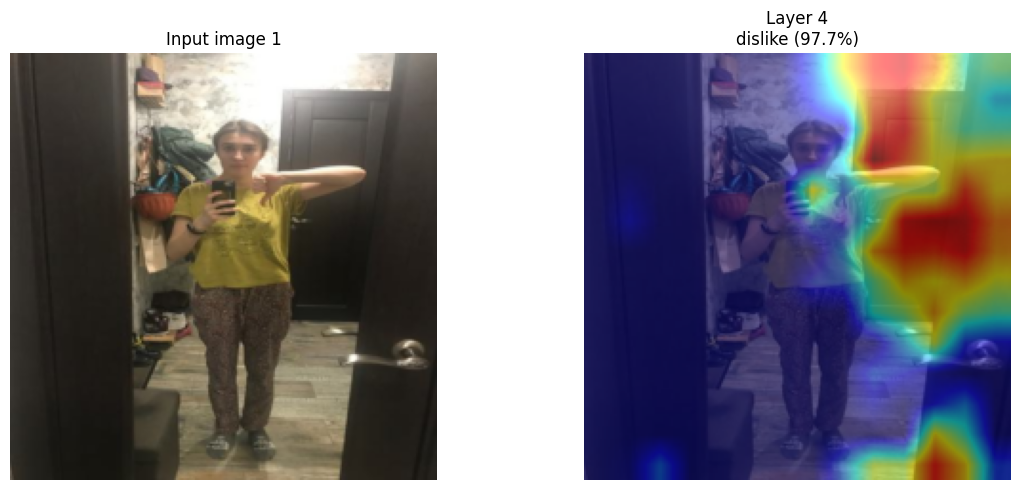

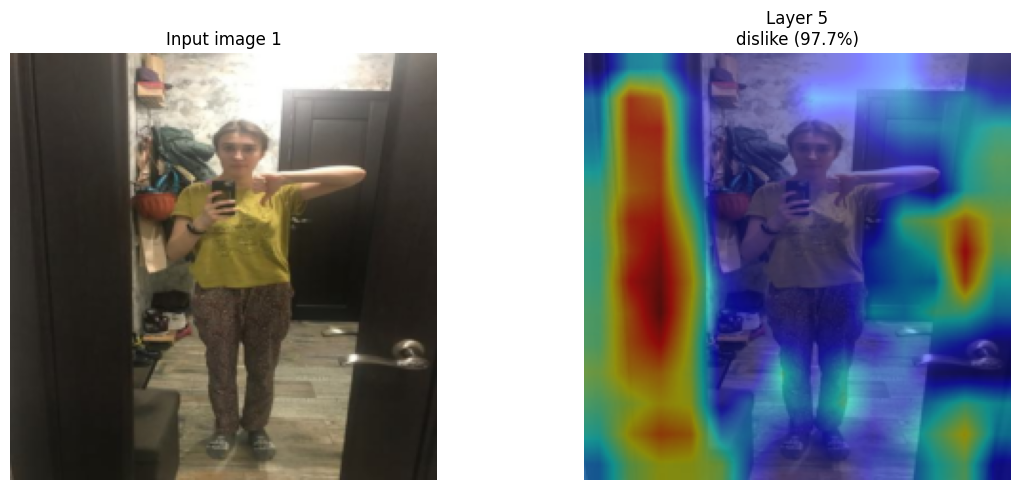

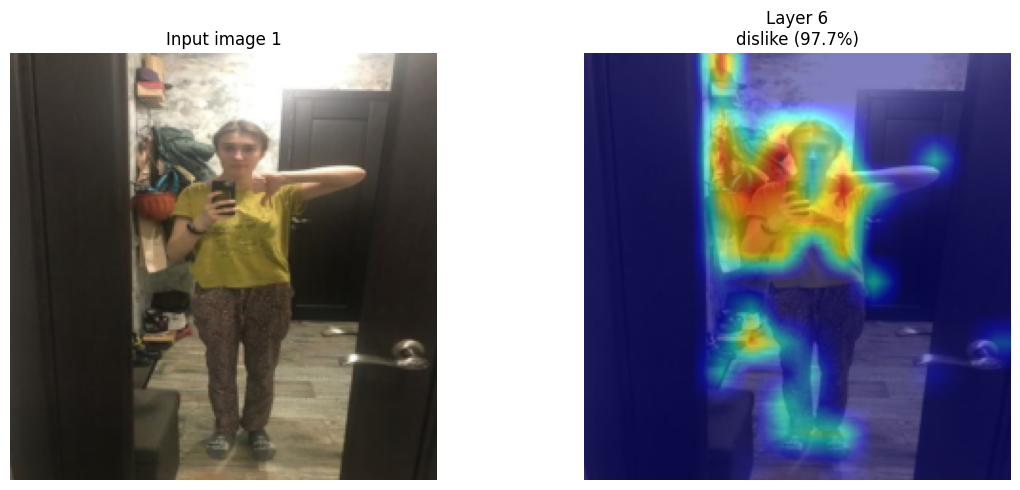

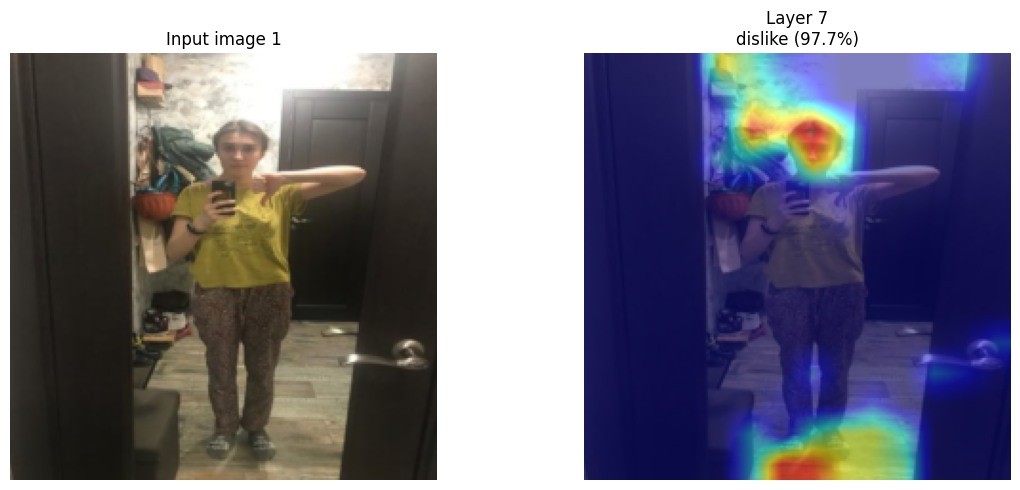

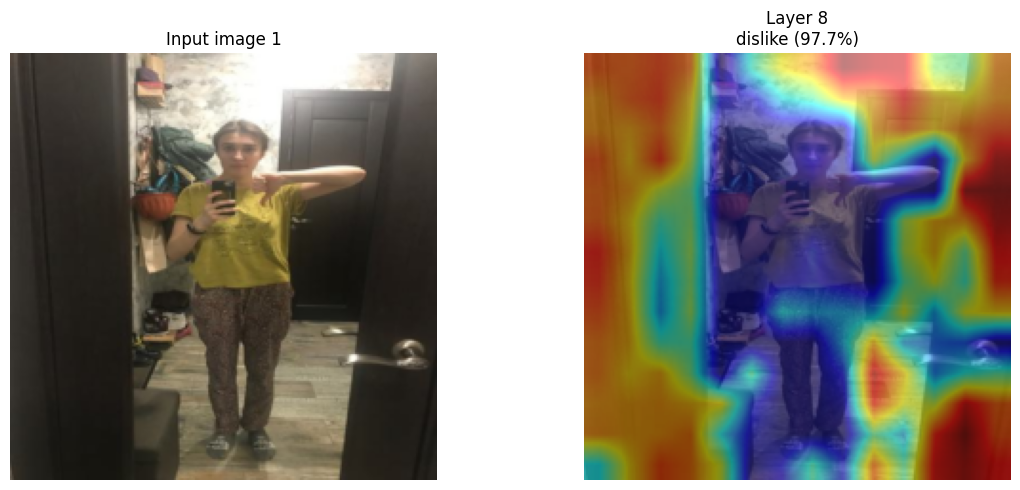

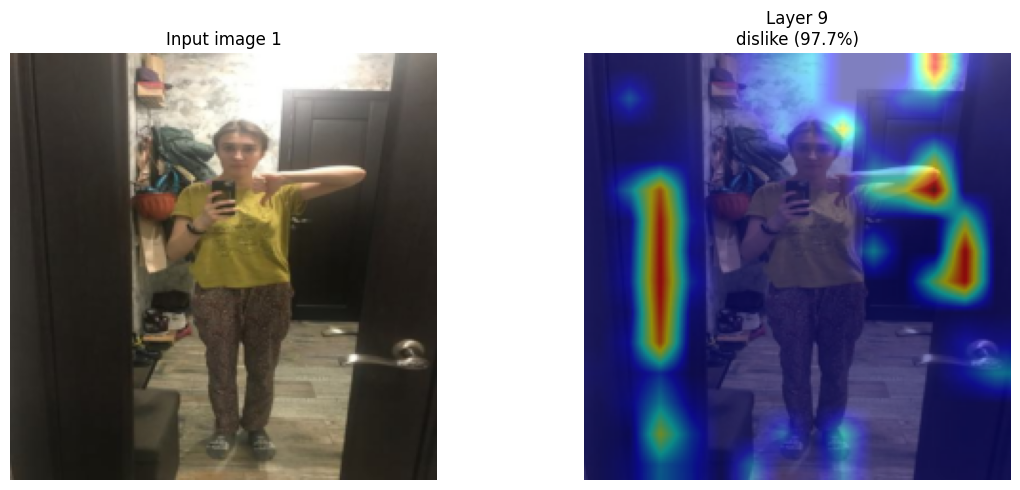

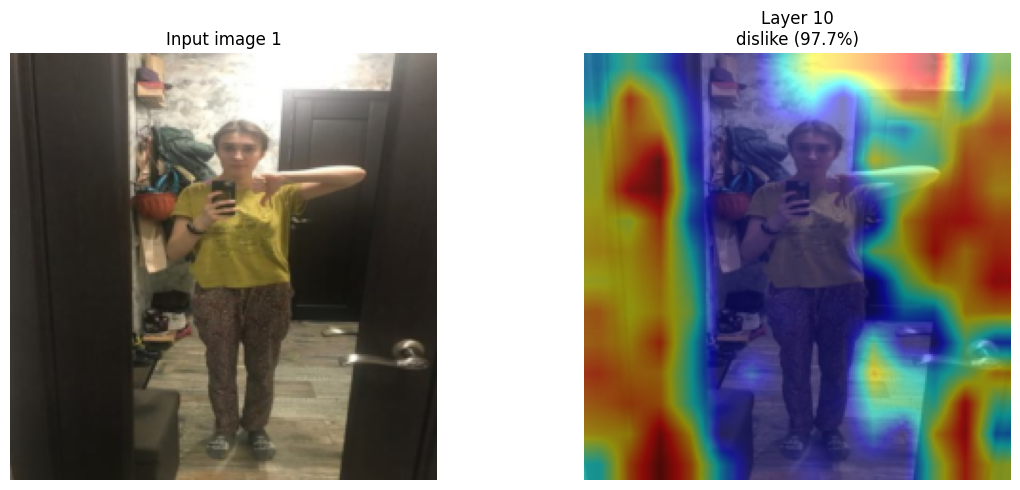

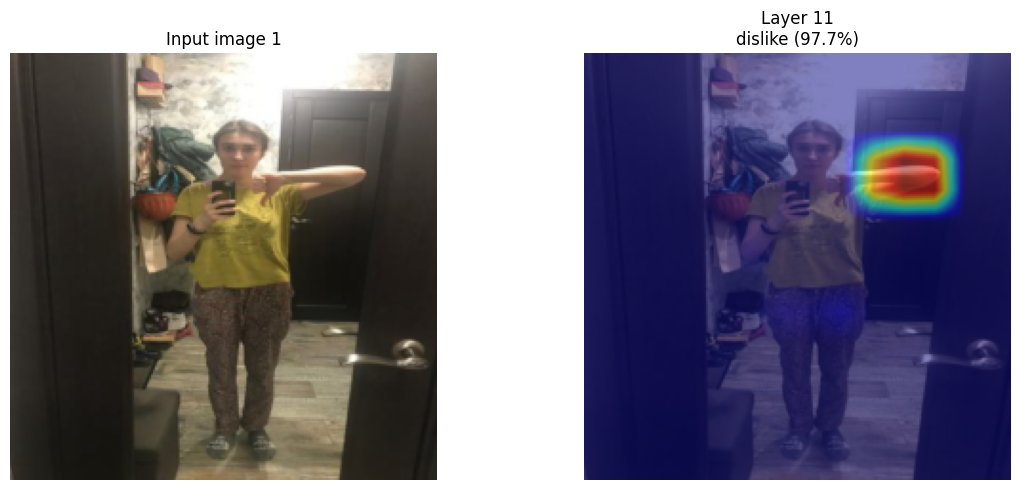

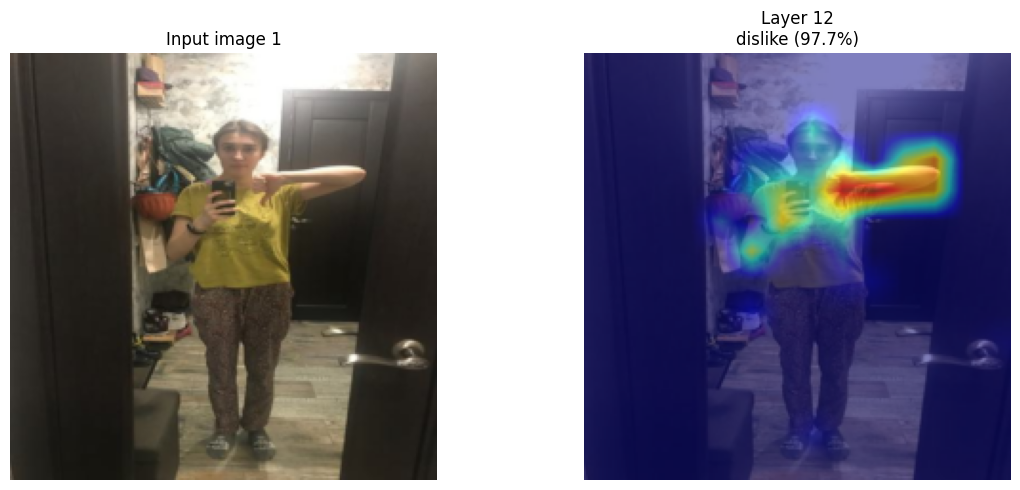

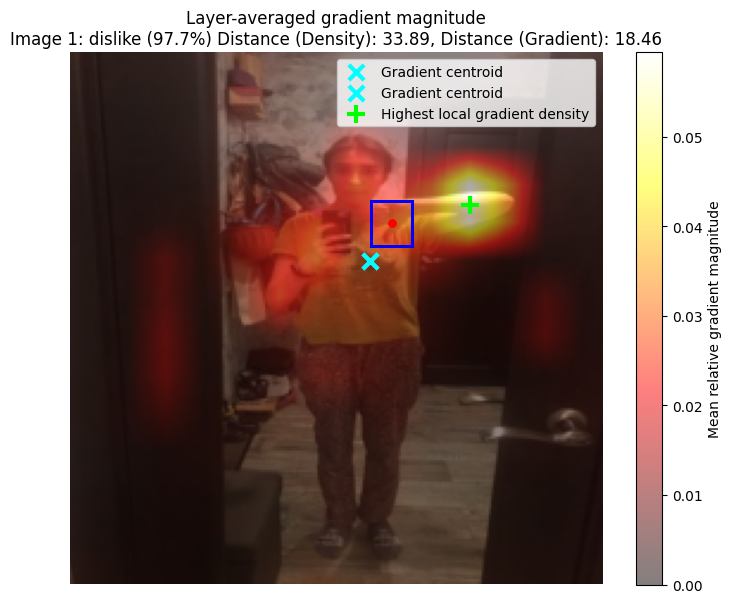

Processing image 51/100


In [ ]:

def GradCAM_visualization(layers, cam_model, prepared_inputs, device, reshape_transform, bbox=None, show_cam=-1):
    layers = list(layers)
    cam_model.eval()
    mean_gradient_maps = []

    output=pd.DataFrame()
    for image_idx, prepared_input in enumerate(prepared_inputs):
        if image_idx % 50== 0:
            print(f"Processing image {image_idx + 1}/{len(prepared_inputs)}")
        input_tensor = prepared_input.to(device)

        if input_tensor.ndim == 3:
            input_tensor = input_tensor.unsqueeze(0)

        display_image = (input_tensor[0].detach().cpu().float() * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

        with torch.no_grad():
            class_name, predicted_class, confidence = model_prediction(input_tensor)

        predicted_class = int(predicted_class)
        confidence = float(confidence)
        normalized_layer_maps = []

        for layer_idx, layer in enumerate(layers):
            with GradCAMPlusPlus(model=cam_model, target_layers=[layer.layernorm_before], reshape_transform=reshape_transform) as cam:

                with torch.enable_grad():
                    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(predicted_class)])[0]

                gradients = cam.activations_and_grads.gradients[0][0]
                gradient_map = gradients.detach().float().abs().mean(dim=0).cpu()
                normalized_map = gradient_map / gradient_map.sum().clamp_min(1e-12)
                normalized_layer_maps.append(normalized_map)

            if image_idx==show_cam:
                cam_image = show_cam_on_image(display_image, grayscale_cam, use_rgb=True, image_weight=0.5)

                fig, axes = plt.subplots(1, 2, figsize=(12, 5))

                axes[0].imshow(display_image)
                axes[0].set_title(f"Input image {image_idx + 1}")
                axes[0].axis("off")
                axes[1].imshow(cam_image)
                axes[1].set_title(f"Layer {layer_idx + 1}\n{class_name} ({confidence:.1%})")
                axes[1].axis("off")
                plt.tight_layout()
                plt.show()
                plt.close(fig)

        mean_gradient_map = torch.stack(normalized_layer_maps, dim=0).mean(dim=0)
        mean_gradient_maps.append(mean_gradient_map)
        resized_map = F.interpolate(mean_gradient_map[None, None], size=display_image.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()
        maximum_Gradient = resized_map.max()


        if image_idx==show_cam:
            fig, ax = plt.subplots(figsize=(7, 6))
            ax.imshow(display_image)
            overlay = ax.imshow(resized_map, cmap="hot", alpha=0.5, vmin=0)
            overlay.set_clim(0, maximum_Gradient)


        weights = np.asarray(resized_map, dtype=np.float64)
        total_weight = weights.sum()

        if np.isfinite(total_weight) and total_weight > 0:
            yy, xx = np.indices(weights.shape)

            gradient_center_x = float((xx * weights).sum() / total_weight)
            gradient_center_y = float((yy * weights).sum() / total_weight)

            if image_idx==show_cam:
                ax.scatter(gradient_center_x, gradient_center_y, color="cyan", marker="x", s=120, linewidths=3, label="Gradient centroid", zorder=15)
                ax.legend(loc="upper right")


        window_size = 15
        gradient_tensor = torch.as_tensor(resized_map, dtype=torch.float32)[None, None]

        density_map = F.avg_pool2d(gradient_tensor, kernel_size=window_size, stride=1)[0, 0].numpy()
        density_y, density_x = np.unravel_index(np.argmax(density_map), density_map.shape)

        # Convert the window's top-left position to its center
        density_x += (window_size - 1) / 2
        density_y += (window_size - 1) / 2
        


        if bbox is not None:
            image_h, image_w = display_image.shape[:2]
            for box in bbox[image_idx]:
                x, y, w, h = map(float, box)

                center = (x * image_w + w * image_w / 2, y * image_h + h * image_h / 2)
                if image_idx==show_cam:
                    rect = plt.Rectangle((x * image_w, y * image_h), w * image_w, h * image_h, edgecolor="blue", facecolor="none", linewidth=2, zorder=10)
                    ax.plot(center[0], center[1], "ro", markersize=5, zorder=11)
                    ax.add_patch(rect)


        dist_center_box_local_density=np.sqrt((density_x - center[0])**2 + (density_y - center[1])**2)
        dist_center_box_gradient_center=np.sqrt((gradient_center_x - center[0])**2 + (gradient_center_y - center[1])**2)




        collect = {"dist_density": dist_center_box_local_density,
                "dist_gradient_center": dist_center_box_gradient_center,
                "Prediction": predicted_class,
                "Image Index": image_idx}
        output = pd.concat([output, pd.DataFrame([collect])], ignore_index=True)



        if image_idx==show_cam:
                ax.scatter(gradient_center_x, gradient_center_y, color="cyan", marker="x", s=120, linewidths=3, label="Gradient centroid", zorder=15)
                ax.legend(loc="upper right")


        if image_idx==show_cam:

            # Density map highest local gradient point
            ax.scatter(density_x, density_y, color="lime", marker="+", s=160, linewidths=3, label="Highest local gradient density", zorder=15)
            ax.legend()


            ax.plot(center[0], center[1], "ro", markersize=5, zorder=11)
            ax.add_patch(rect)
            fig.colorbar(overlay, ax=ax, label="Mean relative gradient magnitude")
            ax.set_title(f"Layer-averaged gradient magnitude\nImage {image_idx + 1}: {class_name} ({confidence:.1%}) Distance (Density): {dist_center_box_local_density:.2f}, Distance (Gradient): {dist_center_box_gradient_center:.2f}")
            ax.axis("off")

            plt.tight_layout()
            plt.show()
            plt.close(fig)

    return output


output=GradCAM_visualization(layers, cam_model, prepared_inputs, device,reshape_transform, bbox=bbox, show_cam=0)


output["ID"]=image_id

In [ ]:
analysis = output.merge(dx, on="ID", how="left")


analysis["Check"] = analysis["Prediction"] == analysis["y"]

analysis=analysis.groupby("Check")[["dist_density", "dist_gradient_center"]].mean()
analysis


,dist_density,dist_gradient_center
Check,,
False,4.482879,28.386189
True,10.392615,18.198316
